In [52]:
#importing libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import LeaveOneOut

In [6]:
#load data
dataset = load_breast_cancer() # load all the data
print(dataset.keys()) # lists the contents of the dataset
print(dataset.data.shape) # shape of the X matrix

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
(569, 30)


Point 1

In [ ]:
#PCA
X = dataset.data
y = dataset.target
X_pca = PCA(n_components=2).fit_transform(X)
print(X_pca.shape)

(569, 2)


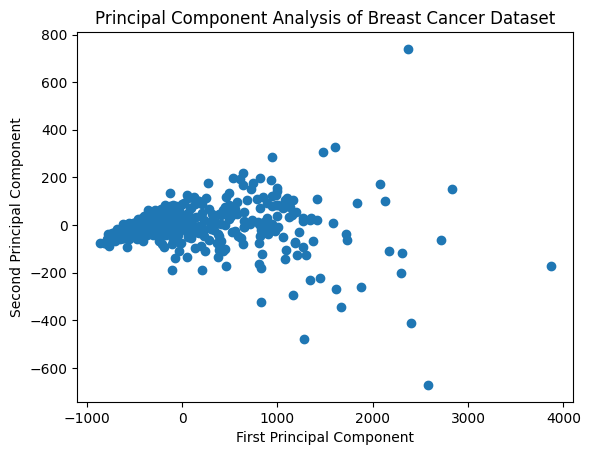

In [9]:
#Plot
plt.plot(X_pca[:, 0], X_pca[:, 1], 'o')
plt.title("Principal Component Analysis of Breast Cancer Dataset")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.show()

Point 2

In [ ]:
#Pearson
correlation =  np.corrcoef(X, rowvar=False)


1.0


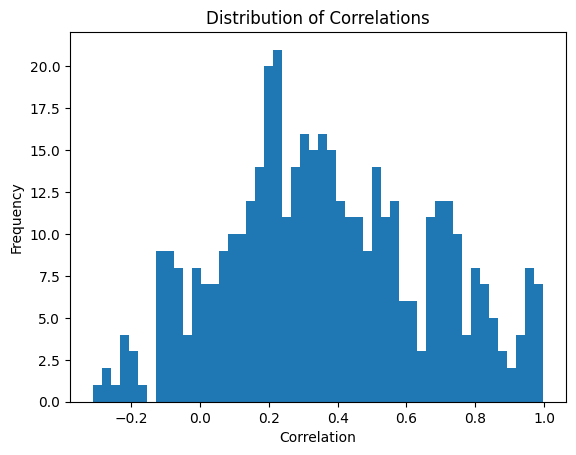

In [18]:
#Histogram
redundancy_off = np.tril(correlation, k=-1).flatten()
redundancy_off = redundancy_off[redundancy_off != 0]
plt.hist(redundancy_off, bins=50)
plt.title("Distribution of Correlations")
plt.xlabel("Correlation")
plt.ylabel("Frequency")
plt.show()

Point 3

In [ ]:
#Feature indexes
feature_names = dataset.feature_names
concavity_index = list(feature_names).index("mean concavity")
worst_area_index = list(feature_names).index("worst area")

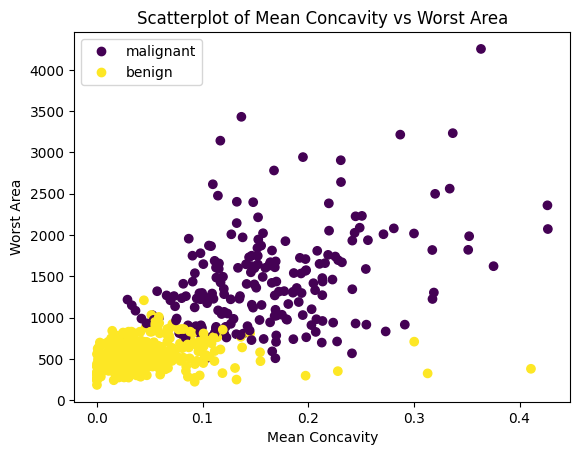

In [ ]:
#Scatterplot
sc = plt.scatter(X[:, concavity_index], X[:, worst_area_index], c=y)
plt.legend(handles=sc.legend_elements()[0], labels=list(dataset.target_names))
plt.title("Scatterplot of Mean Concavity vs Worst Area")
plt.xlabel("Mean Concavity")
plt.ylabel("Worst Area")
plt.show()

Point 4

In [ ]:
#Maxs

#mean
means = np.mean(X, axis=0)
max_mean = np.argmax(means)
print(feature_names[max_mean])

#median
medians = np.median(X, axis=0)
max_median = np.argmax(medians)
print(feature_names[max_median])

#variance
variances = np.var(X, axis=0)
max_variance = np.argmax(variances)    
print(feature_names[max_variance])

worst smoothness
worst area
worst area


Text(0.5, 1.0, 'Violin Plot of Features with Max Mean, Median, and Variance')

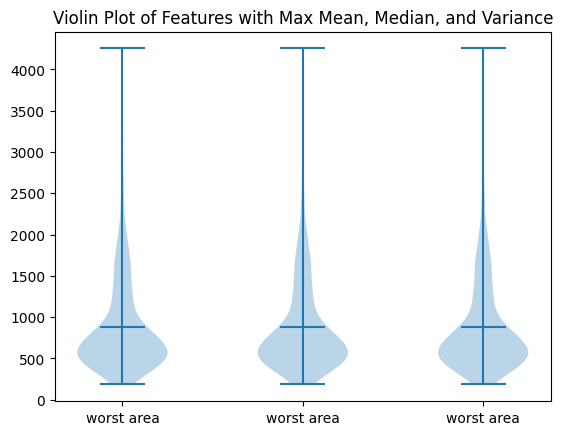

In [32]:
#Violin plot
range_mean = X[:, max_mean]
range_median = X[:, max_median]
range_variance = X[:, max_variance]

plt.violinplot([range_mean, range_median, range_variance], showmeans=True)
plt.xticks([1, 2, 3], [feature_names[max_mean], feature_names[max_median], feature_names[max_variance]])
plt.title("Violin Plot of Features with Max Mean, Median, and Variance")

Point 5

In [ ]:
#splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(455, 30) (114, 30) (455,) (114,)


In [40]:
#fit model
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [41]:
#score
accuracy = model.score(X_test, y_test)
print(accuracy)
print(model.n_iter_)

0.9385964912280702
[2484]


Point 6

In [43]:
#build pipeline
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))

In [46]:
#fit, score the pipeline and iters
pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_test, y_test)
print(accuracy)
iter = pipeline['logisticregression'].n_iter_
print(iter[0])

0.9824561403508771
18


#Point 7

In [50]:
#KFold
accuracies = []
kf = KFold(n_splits=5, shuffle=False)
for train_idx, test_idx in kf.split(X):
    pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]
    pipeline.fit(X_train_fold, y_train_fold)
    accuracy = pipeline.score(X_test_fold, y_test_fold)
    print(accuracy)
    accuracies.append(accuracy)

0.9736842105263158
0.956140350877193
0.9824561403508771
0.9824561403508771
0.9911504424778761


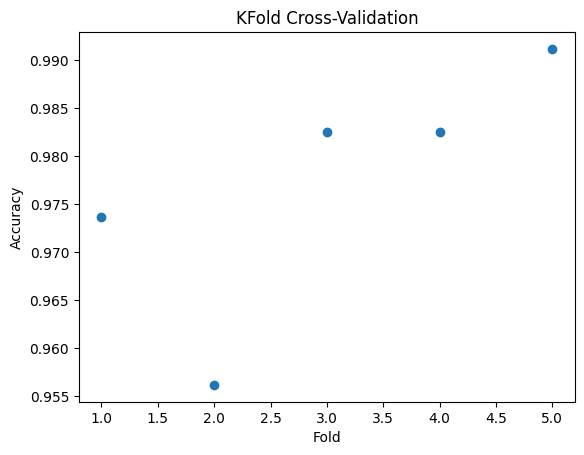

In [51]:
#Plot accuracies
plt.plot(range(1, 6), accuracies, 'o')
plt.title("KFold Cross-Validation")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.show()

Point 7

In [54]:
#Leave One Out
loo_accuracies = []
LOO = LeaveOneOut()
for train_idx, test_idx in LOO.split(X):     # which splitter object?
    pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]
    pipeline.fit(X_train_fold, y_train_fold)
    accuracy = pipeline.score(X_test_fold, y_test_fold)
    loo_accuracies.append(accuracy)


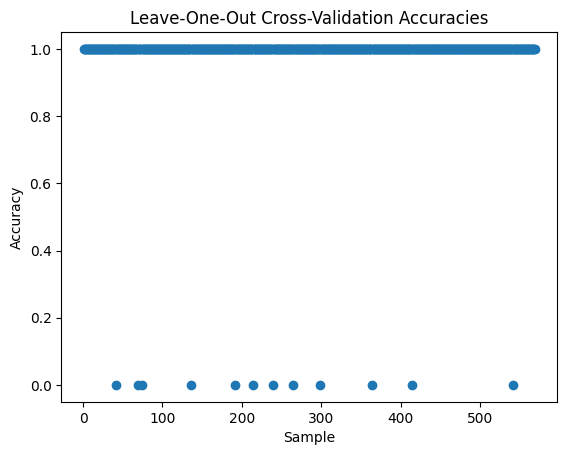

In [56]:
#Scatterplot of accuracies
plt.plot(range(1, len(loo_accuracies) + 1), loo_accuracies, 'o')
plt.title("Leave-One-Out Cross-Validation Accuracies")
plt.xlabel("Sample")
plt.ylabel("Accuracy")
plt.show()